# Lipschitz toy model testin

Following will be a series of tests to see how the performance of the Lipschitz constrained model acts.

In [1]:
import os
import sys
import random
import numpy as np
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tqdm

import monotonicnetworks as lmn

import matplotlib.pyplot as plt


In [138]:
# "Homemade" modules
%autoreload 2
from Toy_utils import sine_function_train_data, gaussian_function_data, BasicDataset, calculate_lipschitz_constant, gaussian_lipschitz_constant, lipschitz_floor_1D
from models import LipschitzModel, UnconstrainedModel
from train_eval import train, predict
#from models import UnconstrainedModel, LipschitzModel
#from train_eval import train, evaluate, predict


## Sine function

Testing the Lipschitz performance on a simple sine function. From the Lipschitz condition we should expect a 1-Lipschitz network to be unable to learn a sine function with a frequency higher than 1, while an unconstrained network should not be limited in this way.

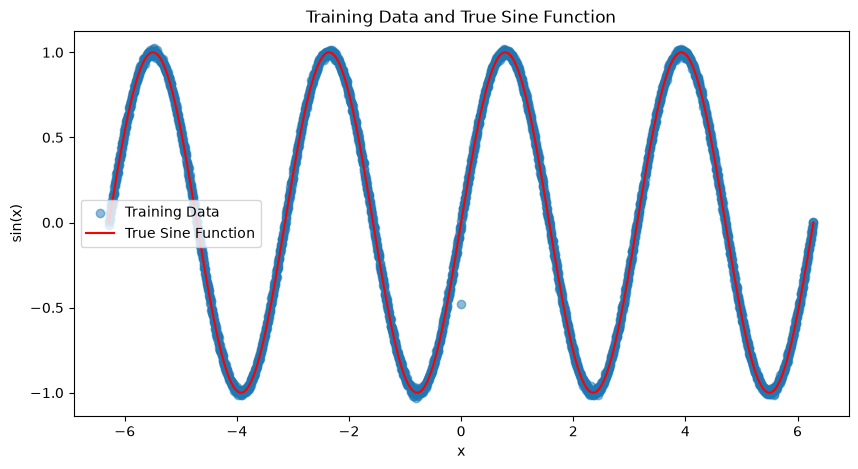

In [ ]:
# Sine function
N = 3000
x_train, y_train, x_linspace, y_linspace = sine_function_train_data(N, frequency=2)

plt.figure(figsize=(10, 5))
plt.scatter(x_train.numpy(), y_train.numpy(), label='Training Data', alpha=0.5)
plt.plot(x_linspace.numpy(), y_linspace.numpy(), color='red', label='True Sine Function')
plt.title('Training Data and True Sine Function')
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.legend()

In [ ]:
# HYPERPARAMETERS
HIDDEN_DIM = 24
N_GROUPS = 8
DEPTH = 5
LEARNING_RATE = 0.0001
NUM_EPOCHS = 5000
MAX_ITER = 1000


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Network
Lipschitz_1_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=1)
Lipschitz_3_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=3)
Unconstrained_model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth = DEPTH)

loss_fn = nn.MSELoss()
optimizer_L1 = torch.optim.Adam(Lipschitz_1_model.parameters(), lr=LEARNING_RATE)
optimizer_L3 = torch.optim.Adam(Lipschitz_3_model.parameters(), lr=LEARNING_RATE)
optimizer_unconstrained = torch.optim.Adam(Unconstrained_model.parameters(), lr=LEARNING_RATE)

In [5]:

# Dataset
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)


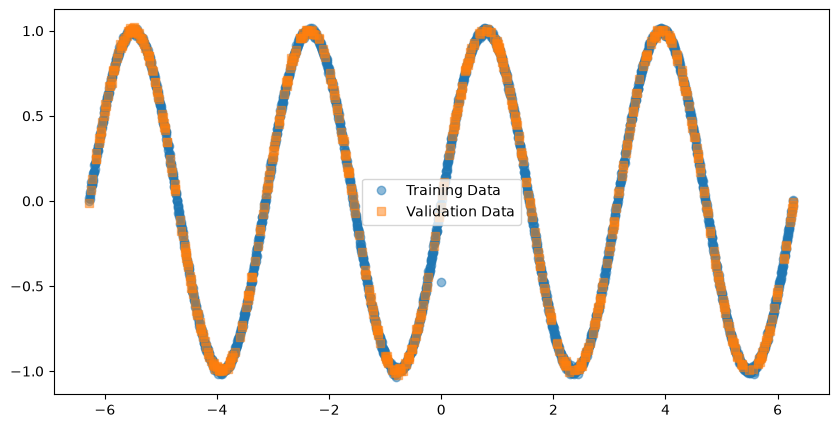

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(x_train.numpy(), y_train.numpy(), 'o', label='Training Data', alpha=0.5)
plt.plot(x_val.numpy(), y_val.numpy(), 's', label='Validation Data', alpha=0.5)
plt.legend()
plt.show()

In [7]:
print(x_train.shape, y_train.shape)
print(x_val.shape, y_val.shape)

torch.Size([2400, 1]) torch.Size([2400, 1])
torch.Size([600, 1]) torch.Size([600, 1])


In [ ]:

train_dataset = BasicDataset(x_train, y_train)
val_dataset = BasicDataset(x_val, y_val)

# Dataloader
trn_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)


In [ ]:
train_losses_L1, val_losses_L1 = train(model =Lipschitz_1_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_L1,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L3, val_losses_L3 = train(model =Lipschitz_3_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_L3,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_unconstrained, val_losses_unconstrained = train(model =Unconstrained_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_unconstrained,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 16
-------------------------------
Epoch 17
-------------------------------
Epoch 18
-------------------------------
Epoch 19
-------------------------------
Epoch 20
-------------------------------
Epoch 21
-------------------------------
Epoch 22
-------------------------------
Epoch 23
-------------------------------
Epoch 24
-------------------------------
Epoch 25
----------------

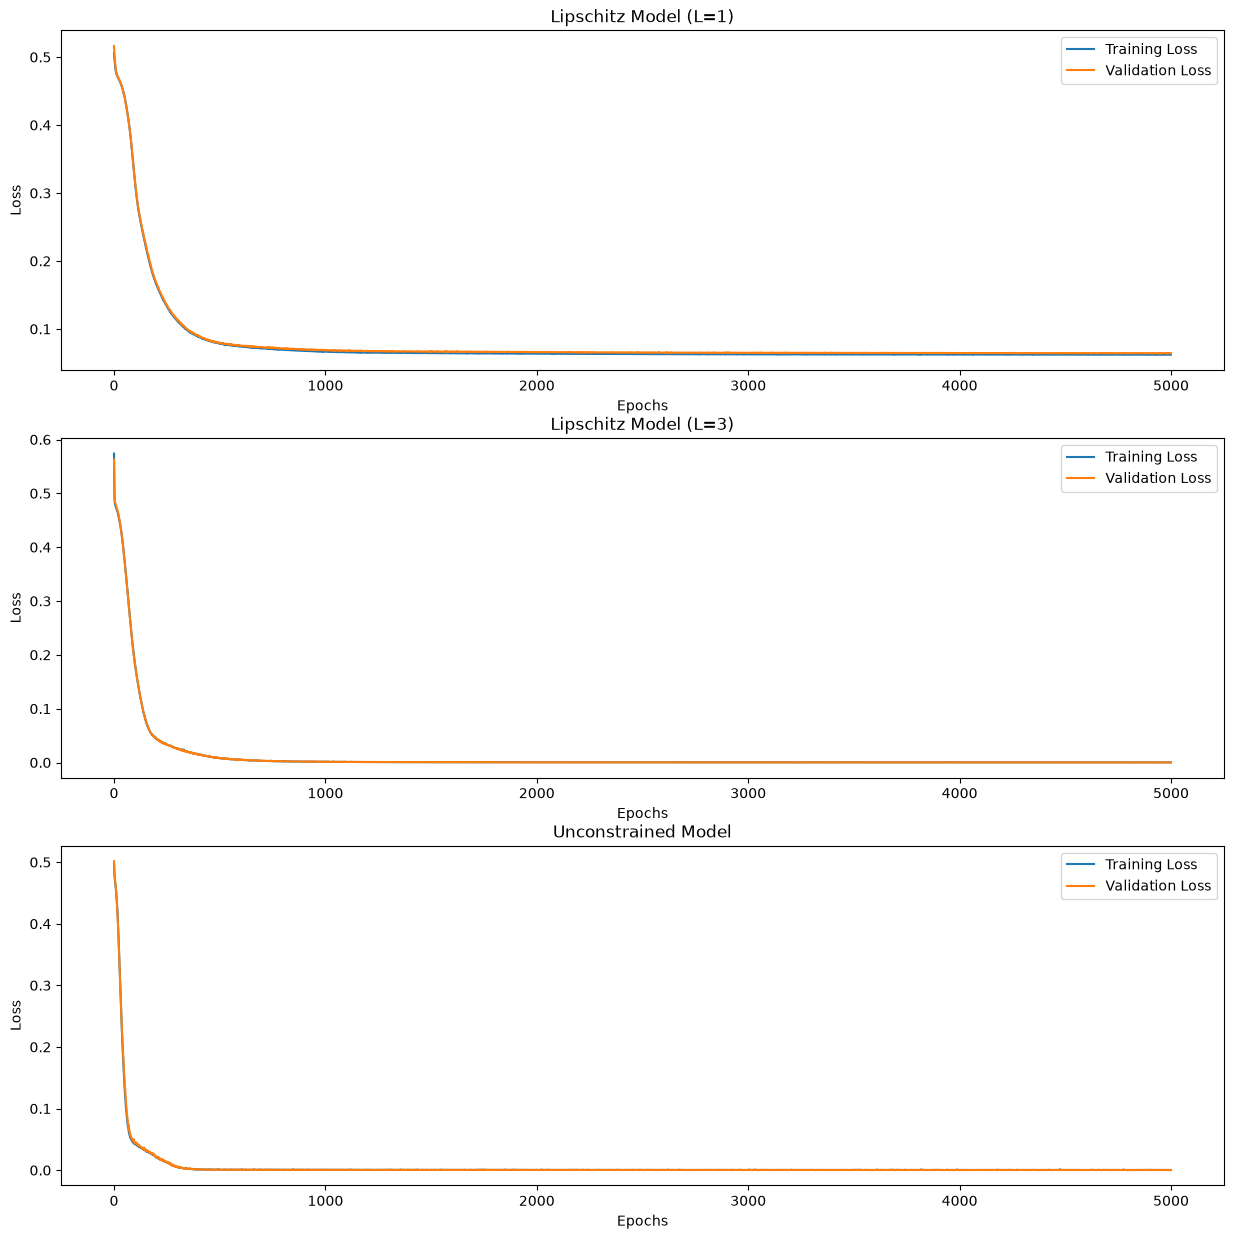

In [11]:
# Plotting training and validation losses
fig, ax = plt.subplots(3, 1, figsize=(15, 15))
ax[0].plot(train_losses_L1, label='Training Loss')
ax[0].plot(val_losses_L1, label='Validation Loss')
ax[0].set_title('Lipschitz Model (L=1)')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
ax[1].plot(train_losses_L3, label='Training Loss')
ax[1].plot(val_losses_L3, label='Validation Loss')
ax[1].set_title('Lipschitz Model (L=3)')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss')
ax[2].plot(train_losses_unconstrained, label='Training Loss')
ax[2].plot(val_losses_unconstrained, label='Validation Loss')
ax[2].set_title('Unconstrained Model')
ax[2].set_xlabel('Epochs')
ax[2].set_ylabel('Loss')
for a in ax:
    a.legend()

plt.savefig('Plots/sine_losses_plot.pdf')
plt.show()


In [ ]:
x_linspace

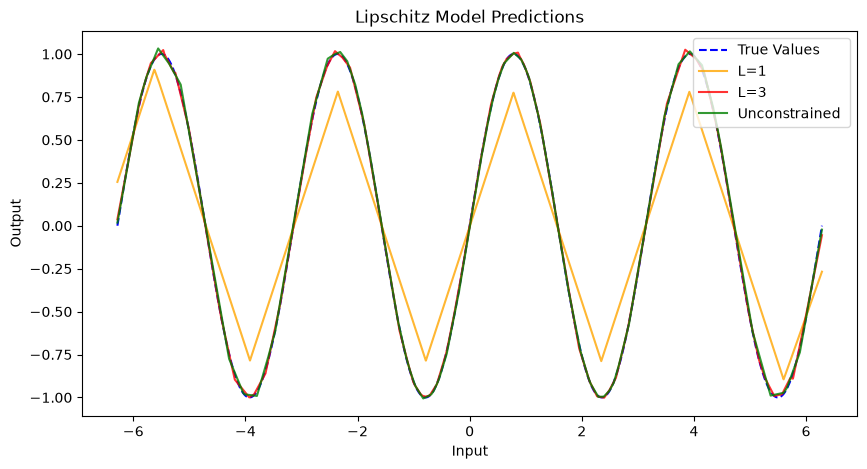

In [ ]:
# Plotting predictions
predictions_1_lipschitz = Lipschitz_1_model(torch.Tensor(x_linspace).view(-1, 1)).detach().numpy()
predictions_3_lipschitz = Lipschitz_3_model(x_linspace).detach().numpy()
predictions_unconstrained = Unconstrained_model(x_linspace).detach().numpy()

plt.figure(figsize=(10, 5))
plt.plot(x_linspace, y_linspace, '--', label='True Values', color='blue')
plt.plot(x_linspace, predictions_1_lipschitz,'-', label='L=1',  color='orange', alpha=0.8)
plt.plot(x_linspace, predictions_3_lipschitz, '-', label='L=3', color='red', alpha=0.8)
plt.plot(x_linspace, predictions_unconstrained,'-', label='Unconstrained ', color='green', alpha=0.8)
plt.xlabel('Input')
plt.ylabel('Output')
plt.legend()
plt.savefig("Plots/sine_fits.pdf")

plt.title('Lipschitz Model Predictions')
plt.show()



In [23]:

# Calculation of predicted Lipschitz constants
lipschitz_constant_L1 = Toy_utils.calculate_lipschitz_constant(Lipschitz_1_model, x_linspace)
lipschitz_constant_L3 = Toy_utils.calculate_lipschitz_constant(Lipschitz_3_model, x_linspace)
lipschitz_constant_unconstrained = Toy_utils.calculate_lipschitz_constant(Unconstrained_model, x_linspace)

print(f"Lipschitz constant of the trained model with L=1: {lipschitz_constant_L1:.4f}")
print(f"Lipschitz constant of the trained model with L=3: {lipschitz_constant_L3:.4f}")
print(f"Lipschitz constant of the trained unconstrained model: {lipschitz_constant_unconstrained:.4f}")

Lipschitz constant of the trained model with L=1: 0.9996
Lipschitz constant of the trained model with L=3: 1.9977
Lipschitz constant of the trained unconstrained model: 2.5397


In [30]:
x_linspace = x_linspace.detach().numpy()

<>:3: SyntaxWarning: invalid escape sequence '\h'
<>:3: SyntaxWarning: invalid escape sequence '\h'
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/3550661950.py:3: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(x_linspace, predictions_1_lipschitz,'-', label=f'L=1, $\hat{{L}}=${lipschitz_constant_L1:.2f} ',  color='orange', alpha=0.8)


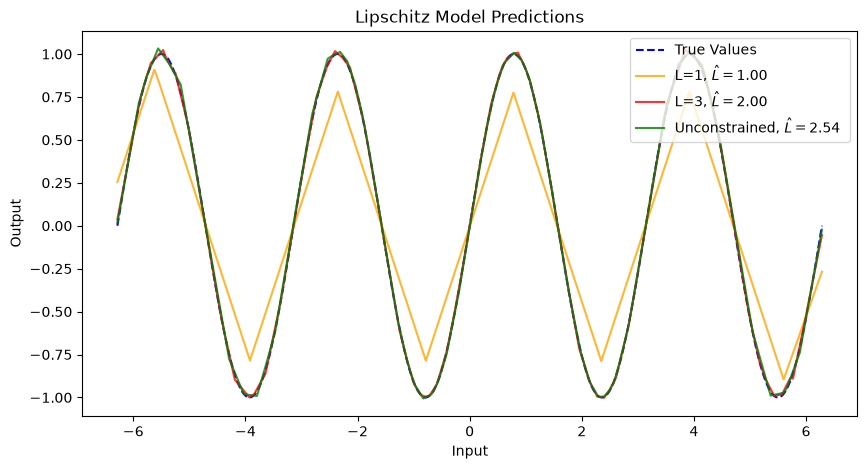

In [43]:
plt.figure(figsize=(10, 5))
plt.plot(x_linspace, y_linspace, '--', label='True Values', color='blue')
plt.plot(x_linspace, predictions_1_lipschitz,'-', label=f'L=1, $\hat{{L}}=${lipschitz_constant_L1:.2f} ',  color='orange', alpha=0.8)
plt.plot(x_linspace, predictions_3_lipschitz, '-', label=rf'L=3, $\hat{{L}}=${lipschitz_constant_L3:.2f} ', color='red', alpha=0.8)
plt.plot(x_linspace, predictions_unconstrained,'-', label=rf'Unconstrained, $\hat{{L}}=${lipschitz_constant_unconstrained:.2f} ', color='green', alpha=0.8)
plt.xlabel('Input')
plt.ylabel('Output')
plt.legend(loc = 'upper right')
plt.savefig("Plots/sine_fits.pdf")
plt.title('Lipschitz Model Predictions')
plt.show()

<>:16: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
<>:16: SyntaxWarning: invalid escape sequence '\h'
<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:18: SyntaxWarning: invalid escape sequence '\h'
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/1851831182.py:16: SyntaxWarning: invalid escape sequence '\h'
  plt.hist(abs_errors_L1, bins=30, alpha=0.5, label=f'L=1, $\hat{{L}}=${mean_abs_error_L1:.3f} ', color='orange', density=True)
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/1851831182.py:17: SyntaxWarning: invalid escape sequence '\h'
  plt.hist(abs_errors_L3, bins=30, alpha=0.5, label=f'L=3, $\hat{{L}}=${mean_abs_error_L3:.3f} ', color='red', density=True)
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/1851831182.py:18: SyntaxWarning: invalid escape sequence '\h'
  plt.hist(abs_errors_unconstrained, bins=30, alpha=0.5, lab

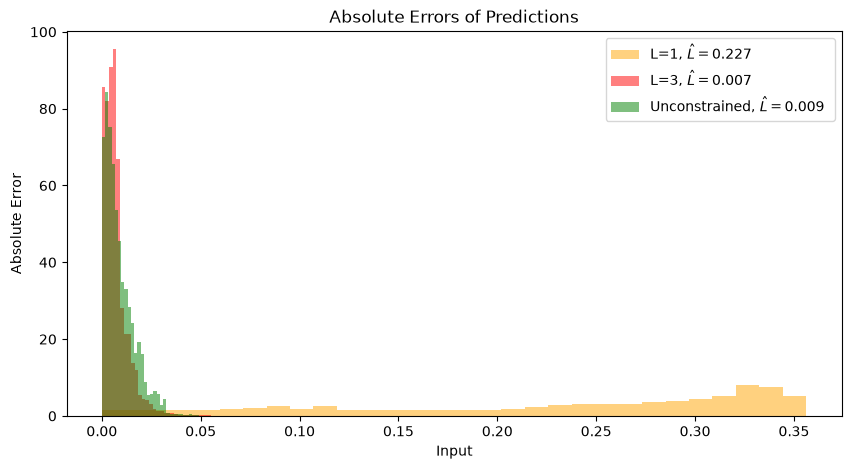

Mean Absolute Error (L1 model): tensor(0.2265)
Mean Absolute Error (L3 model): tensor(0.0070)
Mean Absolute Error (Unconstrained Model): tensor(0.0089)


In [45]:
# Errors
errors_L1 = y_linspace - predictions_1_lipschitz
errors_L3 = y_linspace - predictions_3_lipschitz
errors_unconstrained = y_linspace - predictions_unconstrained

abs_errors_L1 = np.abs(errors_L1)
abs_errors_L3 = np.abs(errors_L3)
abs_errors_unconstrained = np.abs(errors_unconstrained)

mean_abs_error_L1 = torch.mean(abs_errors_L1)
mean_abs_error_L3 = torch.mean(abs_errors_L3)
mean_abs_error_unconstrained = torch.mean(abs_errors_unconstrained)

# Plotting absolute errors
plt.figure(figsize=(10, 5))
plt.hist(abs_errors_L1, bins=30, alpha=0.5, label=f'L=1, $\hat{{L}}=${mean_abs_error_L1:.3f} ', color='orange', density=True)
plt.hist(abs_errors_L3, bins=30, alpha=0.5, label=f'L=3, $\hat{{L}}=${mean_abs_error_L3:.3f} ', color='red', density=True)
plt.hist(abs_errors_unconstrained, bins=30, alpha=0.5, label=f'Unconstrained, $\hat{{L}}=${mean_abs_error_unconstrained:.3f} ', color='green', density=True)
plt.xlabel('Input')
plt.ylabel('Absolute Error')
plt.legend()
plt.savefig("Plots/sine_abs_errors.pdf")
plt.title('Absolute Errors of Predictions')
plt.show()

print("Mean Absolute Error (L1 model):", mean_abs_error_L1)
print("Mean Absolute Error (L3 model):", mean_abs_error_L3)
print("Mean Absolute Error (Unconstrained Model):", mean_abs_error_unconstrained)

This shows that the Lipschitz constraing functions somewhat as a regularizer, limiting the gradients of the network. Coincidentally it performs better than the unconstrained network on smaller frequencies.Also, increasing the Lipschitz constant for the network allows it to learn higher frequency functions that the unconstrained model struggles with. This is less intuitive becuase we are using linear layers with weight normalization for the L-Lipschitz networks. However, the GroupSort activation function works as a non-linear activation function that allows the network to learn more complex functions. None of this is strictly new information as we know that the GroupSort activation is a universal approximator for the class of L-Lipschitz functions, something ReLU is not.

Notably, it is not surprising that neither network gets a particularily good fit on the sine function as linear networks lack the inductive bias to learn periodic functions well.

## Gaussian function

IDÈ: Lag et heatmap med loss for kombinasjoner av forskjellige Lipschitz-konstanter mot bredde på gauss fordelingene. Mean verdien er ikke så veldig interessant, og normalisering av høyde kan alltids gjøres i preprocossessering.

Lipschitz constant of the Gaussian function with sigma=0.1: 24.1971


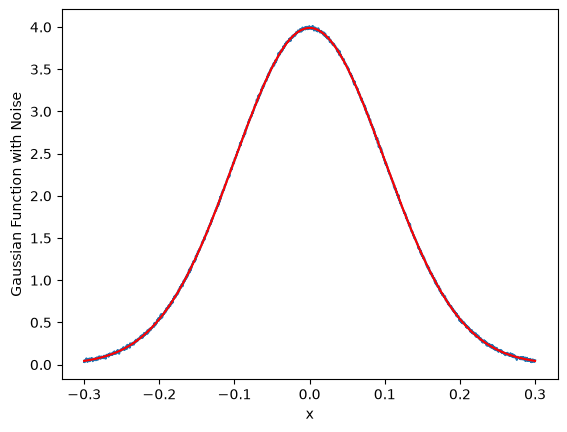

In [172]:
N = 2000
MU = 0
SIGMA = 0.1
NOISE_MAGNITUDE = 0.01

x_gaussian_train, y_gaussian_train, x_gaussian_linspace, y_gaussian_linspace = gaussian_function_data(N=N, mu=MU, sigma=SIGMA, noise_magnitude=NOISE_MAGNITUDE)
plt.plot(x_gaussian_train.numpy(), y_gaussian_train.numpy())
plt.xlabel('x')
plt.ylabel('Gaussian Function with Noise')
plt.plot(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), color='red', label='True Gaussian Function')
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {gaussian_lipschitz_constant(SIGMA):.4f}")

In [173]:


print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {gaussian_lipschitz_constant(SIGMA):.4f}")

Lipschitz constant of the Gaussian function with sigma=0.1: 24.1971


In [174]:
# Floor of the Gaussian function for an L-Lipschitz function



In [175]:
# Splitting data into training and validation sets
x_gaussian_train, x_gaussian_val, y_gaussian_train, y_gaussian_val = train_test_split(x_gaussian_train, y_gaussian_train, test_size=0.2, random_state=42)

# Dataloaders for Gaussian data
train_gaussian_dataset = BasicDataset(x_gaussian_train, y_gaussian_train)
val_gaussian_dataset = BasicDataset(x_gaussian_val, y_gaussian_val)

train_gaussian_loader = DataLoader(train_gaussian_dataset, batch_size=32, shuffle=True)
val_gaussian_loader = DataLoader(val_gaussian_dataset, batch_size=32, shuffle=False)

In [176]:
# Setting up contrasting models
HIDDEN_DIM = 24
N_GROUPS = 8
DEPTH = 5
LEARNING_RATE = 0.0001

Lipschitz_1_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=1)
Lipschitz_3_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=3)
Lipschitz_10_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=10)
Lipschitz_20_model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=20)
Unconstrained_model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth = DEPTH)

loss_fn = nn.MSELoss()
optimizer_L1 = torch.optim.Adam(Lipschitz_1_model.parameters(), lr=LEARNING_RATE)
optimizer_L3 = torch.optim.Adam(Lipschitz_3_model.parameters(), lr=LEARNING_RATE)
optimizer_L10 = torch.optim.Adam(Lipschitz_10_model.parameters(), lr=LEARNING_RATE)
optimizer_L20 = torch.optim.Adam(Lipschitz_20_model.parameters(), lr=LEARNING_RATE)
optimizer_unconstrained = torch.optim.Adam(Unconstrained_model.parameters(), lr=LEARNING_RATE)

In [177]:
# Training and evaluating the models on the Gaussian data
NUM_EPOCHS = 1000
MAX_ITER = 100
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_losses_L1, val_losses_L1 = train(model =Lipschitz_1_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L1,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L3, val_losses_L3 = train(model =Lipschitz_3_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L3,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L10, val_losses_L10 = train(model =Lipschitz_10_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L10,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_L20, val_losses_L20 = train(model =Lipschitz_20_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_L20,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

train_losses_unconstrained, val_losses_unconstrained = train(model =Unconstrained_model,
    train_loader = train_gaussian_loader,
    val_loader = val_gaussian_loader,
    optimizer = optimizer_unconstrained,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = MAX_ITER,
    device = device)

Epoch 1: Train Loss: 4.6830, Val Loss: 3.9522
Epoch 51: Train Loss: 1.9648, Val Loss: 1.7950
Epoch 101: Train Loss: 1.7900, Val Loss: 1.6344
Epoch 151: Train Loss: 1.7474, Val Loss: 1.6012
Epoch 201: Train Loss: 1.7428, Val Loss: 1.5939
Epoch 251: Train Loss: 1.7421, Val Loss: 1.5960
Epoch 301: Train Loss: 1.7413, Val Loss: 1.5949
Epoch 351: Train Loss: 1.7414, Val Loss: 1.5955
Epoch 401: Train Loss: 1.7414, Val Loss: 1.5957
Early stopping triggered.
Epoch 1: Train Loss: 5.8277, Val Loss: 4.9886
Epoch 51: Train Loss: 1.9280, Val Loss: 1.7664
Epoch 101: Train Loss: 1.5483, Val Loss: 1.4188
Epoch 151: Train Loss: 1.3360, Val Loss: 1.2261
Epoch 201: Train Loss: 1.3240, Val Loss: 1.2157
Epoch 251: Train Loss: 1.3232, Val Loss: 1.2160
Epoch 301: Train Loss: 1.3229, Val Loss: 1.2158
Epoch 351: Train Loss: 1.3225, Val Loss: 1.2156
Epoch 401: Train Loss: 1.3226, Val Loss: 1.2164
Epoch 451: Train Loss: 1.3220, Val Loss: 1.2157
Epoch 501: Train Loss: 1.3218, Val Loss: 1.2134
Epoch 551: Train Los

<function matplotlib.pyplot.show(close=None, block=None)>

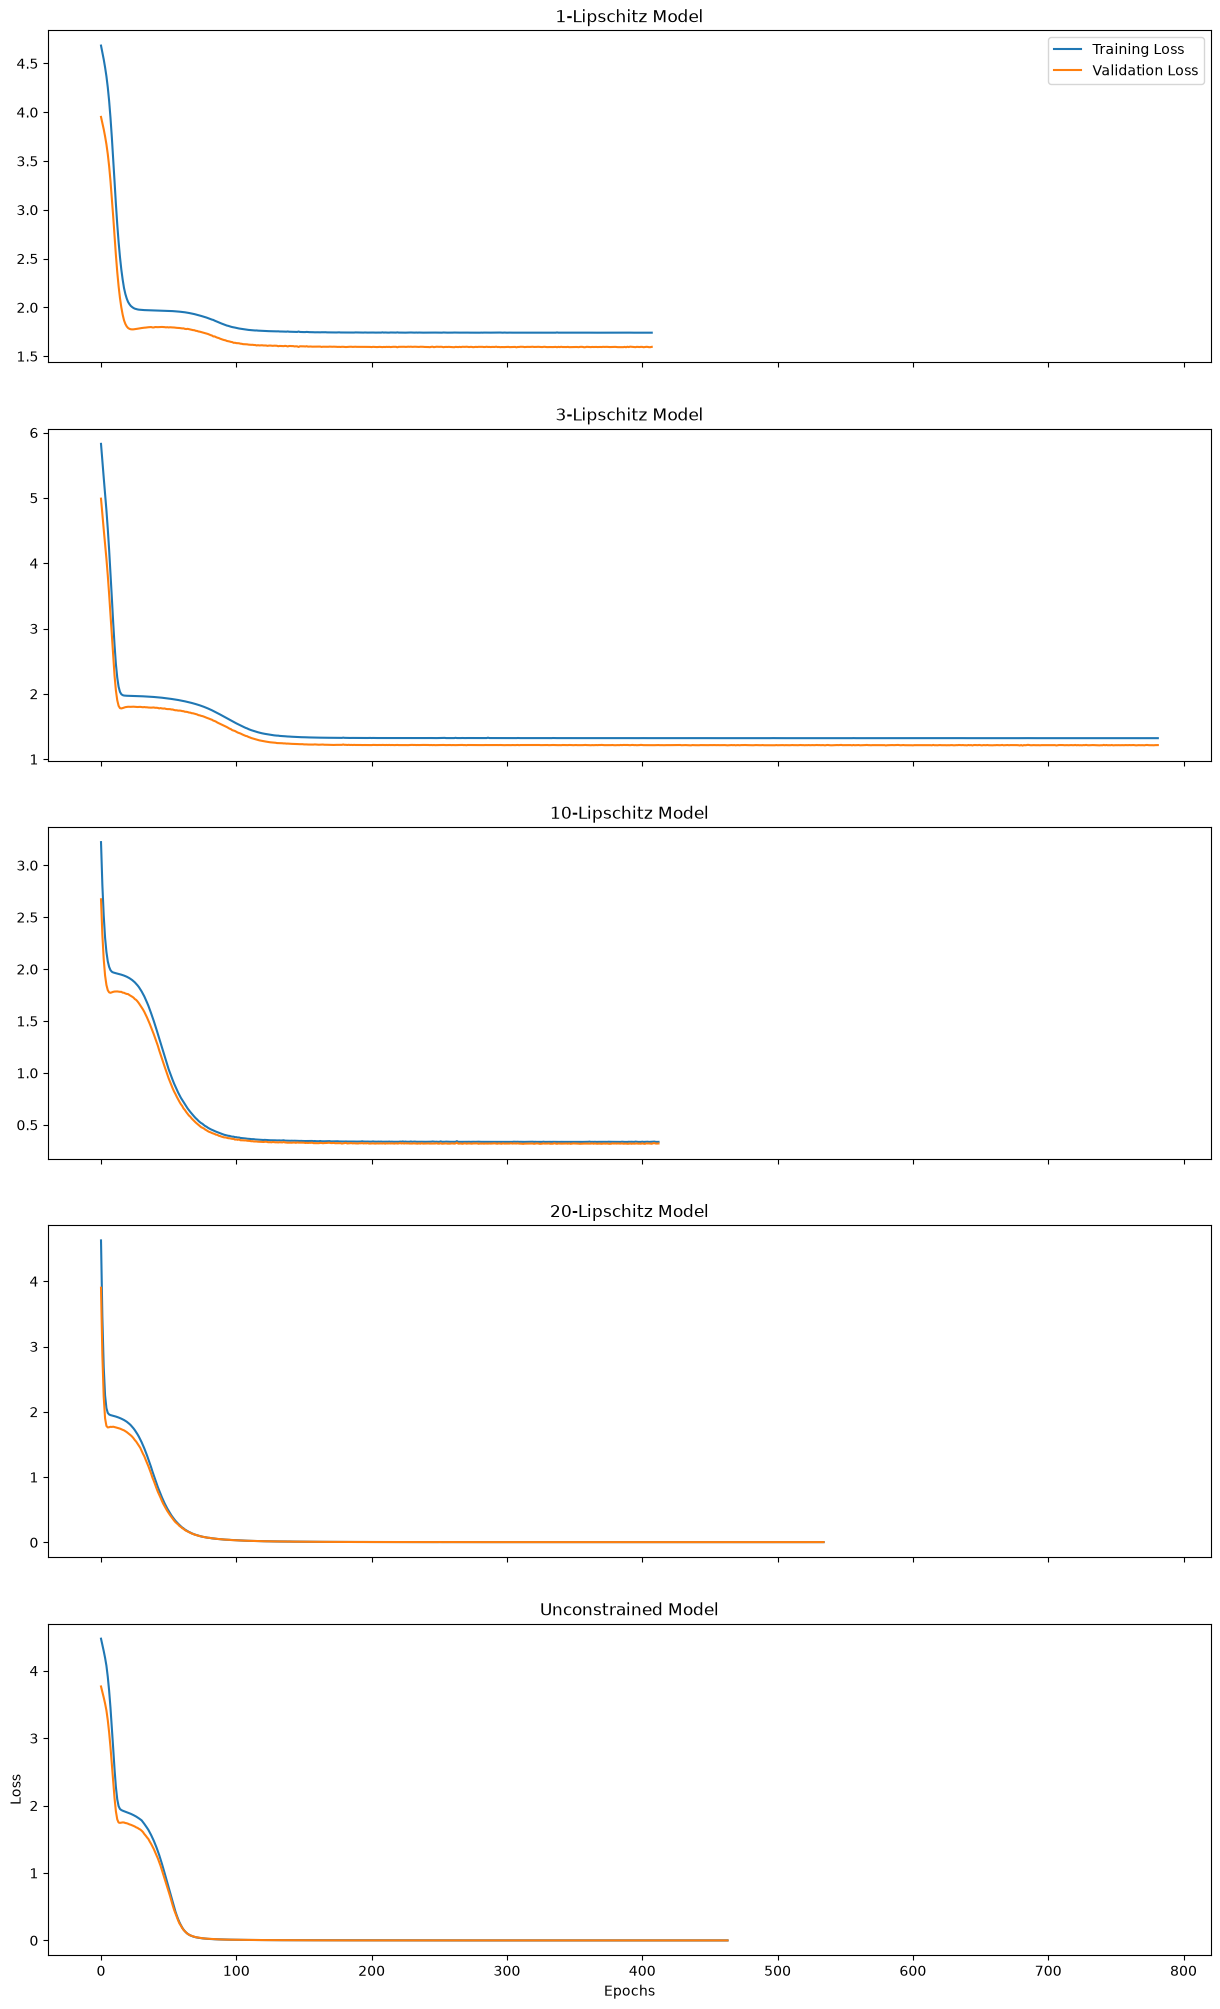

In [178]:
# Check training losses
fig, axs = plt.subplots(5, 1, sharex=True, figsize=(15, 25))
axs[0].set_title("1-Lipschitz Model")
axs[0].plot(train_losses_L1, label='Training Loss')
axs[0].plot(val_losses_L1, label='Validation Loss')
axs[1].set_title("3-Lipschitz Model")
axs[1].plot(train_losses_L3, label='Training Loss (Lipschitz Model, L=3)')
axs[1].plot(val_losses_L3, label='Validation Loss (Lipschitz Model, L=3)')
axs[2].set_title("10-Lipschitz Model")
axs[2].plot(train_losses_L10, label='Training Loss (Lipschitz Model, L=10)')
axs[2].plot(val_losses_L10, label='Validation Loss (Lipschitz Model, L=10)')
axs[3].set_title("20-Lipschitz Model")
axs[3].plot(train_losses_L20, label='Training Loss (Lipschitz Model, L=20)')
axs[3].plot(val_losses_L20, label='Validation Loss (Lipschitz Model, L=20)')
axs[4].set_title("Unconstrained Model")
axs[4].plot(train_losses_unconstrained, label='Training Loss (Unconstrained Model)')
axs[4].plot(val_losses_unconstrained, label='Validation Loss (Unconstrained Model)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
axs[0].legend()
#axs[1].legend()
plt.show

In [179]:
# Predictions
lipschitz_1_predictions = Lipschitz_1_model(x_gaussian_linspace).detach().numpy()
lipschitz_3_predictions = Lipschitz_3_model(x_gaussian_linspace).detach().numpy()
lipschitz_10_predictions = Lipschitz_10_model(x_gaussian_linspace).detach().numpy()
lipschitz_20_predictions = Lipschitz_20_model(x_gaussian_linspace).detach().numpy()
unconstrained_predictions = Unconstrained_model(x_gaussian_linspace).detach().numpy()

# Calculating Lipschitz constants for the trained models
lipschitz_constant_L1 = calculate_lipschitz_constant(Lipschitz_1_model, x_gaussian_linspace)
lipschitz_constant_L3 = calculate_lipschitz_constant(Lipschitz_3_model, x_gaussian_linspace)
lipschitz_constant_L10 = calculate_lipschitz_constant(Lipschitz_10_model, x_gaussian_linspace)
lipschitz_constant_L20 = calculate_lipschitz_constant(Lipschitz_20_model, x_gaussian_linspace)
lipschitz_constant_unconstrained = calculate_lipschitz_constant(Unconstrained_model, x_gaussian_linspace)
true_lipschitz_constant = gaussian_lipschitz_constant(SIGMA)


<>:4: SyntaxWarning: invalid escape sequence '\h'
<>:5: SyntaxWarning: invalid escape sequence '\h'
<>:6: SyntaxWarning: invalid escape sequence '\h'
<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:8: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\h'
<>:4: SyntaxWarning: invalid escape sequence '\h'
<>:5: SyntaxWarning: invalid escape sequence '\h'
<>:6: SyntaxWarning: invalid escape sequence '\h'
<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:8: SyntaxWarning: invalid escape sequence '\h'
<>:9: SyntaxWarning: invalid escape sequence '\h'
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/3925405915.py:4: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(x_gaussian_linspace.numpy(), lipschitz_1_predictions, label=f'L=1, $\hat{{L}}$={lipschitz_constant_L1:.2f}', color='orange')
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/3925405915.py:5: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(x

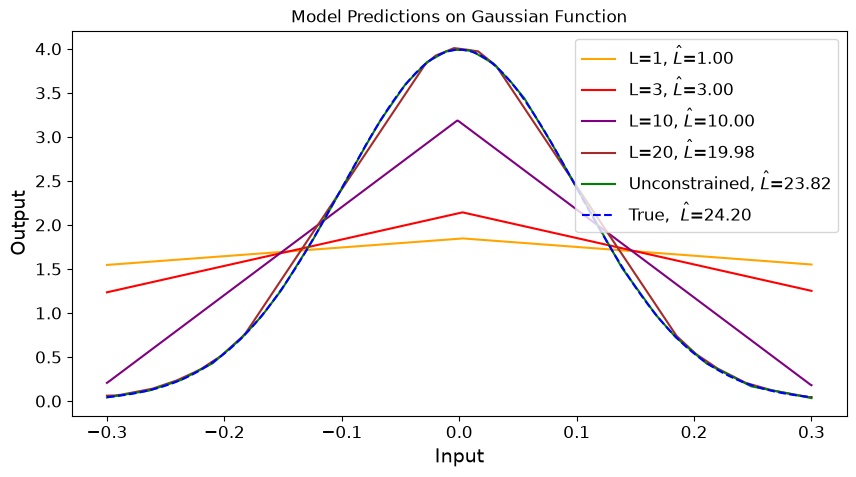

In [180]:

# Plotting predictions
plt.figure(figsize=(10, 5))
#plt.plot(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), label='True Values', color='blue')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_1_predictions, label=f'L=1, $\hat{{L}}$={lipschitz_constant_L1:.2f}', color='orange')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_3_predictions, label=f'L=3, $\hat{{L}}$={lipschitz_constant_L3:.2f}', color='red')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_10_predictions, label=f'L=10, $\hat{{L}}$={lipschitz_constant_L10:.2f}', color='purple')
plt.plot(x_gaussian_linspace.numpy(), lipschitz_20_predictions, label=f'L=20, $\hat{{L}}$={lipschitz_constant_L20:.2f}', color='brown')
plt.plot(x_gaussian_linspace.numpy(), unconstrained_predictions, label=f'Unconstrained, $\hat{{L}}$={lipschitz_constant_unconstrained:.2f}', color='green')
plt.plot(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), '--' , label=f'True,  $\hat{{L}}$={true_lipschitz_constant:.2f}', color='blue')
plt.xlabel('Input', fontsize=14)
plt.ylabel('Output', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.savefig('Plots/gaussian_narrow_fit.pdf')
plt.title('Model Predictions on Gaussian Function')
plt.show()

In [186]:
# Area for the different predictions
lipschitz_1_area = np.trapezoid(lipschitz_1_predictions.flatten(), x_gaussian_linspace.flatten())
lipschitz_3_area = np.trapezoid(lipschitz_3_predictions.flatten(), x_gaussian_linspace.flatten())
lipschitz_10_area = np.trapezoid(lipschitz_10_predictions.flatten(), x_gaussian_linspace.flatten())
lipschitz_20_area = np.trapezoid(lipschitz_20_predictions.flatten(), x_gaussian_linspace.flatten())
unconstrained_area = np.trapezoid(unconstrained_predictions.flatten(), x_gaussian_linspace.flatten())
true_area = np.trapezoid(y_gaussian_linspace.flatten(), x_gaussian_linspace.flatten())

print(f"Area under the curve for L=1 model: {lipschitz_1_area:.4f}")
print(f"Area under the curve for L=3 model: {lipschitz_3_area:.4f}")
print(f"Area under the curve for L=10 model: {lipschitz_10_area:.4f}")
print(f"Area under the curve for L=20 model: {lipschitz_20_area:.4f}")
print(f"Area under the curve for Unconstrained model: {unconstrained_area:.4f}")
print(f"Area under the curve for True Gaussian function: {true_area:.4f}")

Area under the curve for L=1 model: 1.0185
Area under the curve for L=3 model: 1.0157
Area under the curve for L=10 model: 1.0138
Area under the curve for L=20 model: 1.0050
Area under the curve for Unconstrained model: 0.9976
Area under the curve for True Gaussian function: 0.9973


In [ ]:
# The cost of the different Lipschitz constants


/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/2585539575.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  lipschitz_1_errors = y_gaussian_linspace - lipschitz_1_predictions
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/2585539575.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  lipschitz_3_errors = y_gaussian_linspace - lipschitz_3_predictions
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/2585539575.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  unconstrained_errors = y_gaussian_linspace - unconstrained_predictions
/var/folders/3s/v0d_3x_x5mz71f51j0_51f2h0000gn/T/ipykernel_83761/2585539575.py:6: DeprecationWarning: __array_wrap__ must accept contex

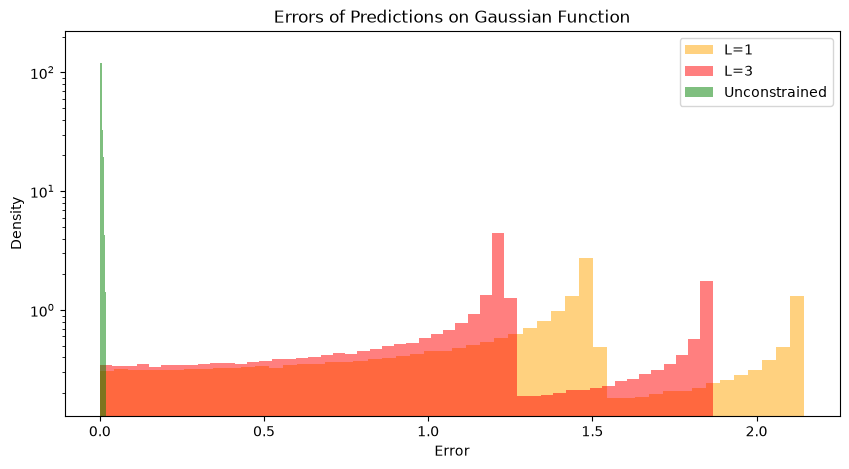

In [181]:
# Errors
lipschitz_1_errors = y_gaussian_linspace - lipschitz_1_predictions
lipschitz_3_errors = y_gaussian_linspace - lipschitz_3_predictions
unconstrained_errors = y_gaussian_linspace - unconstrained_predictions

abs_errors_L1 = np.abs(lipschitz_1_errors)
abs_errors_L3 = np.abs(lipschitz_3_errors)
abs_errors_unconstrained = np.abs(unconstrained_errors)

plt.figure(figsize=(10, 5))
plt.hist(abs_errors_L1, bins=50, alpha=0.5, label='L=1', color='orange', density=True)
plt.hist(abs_errors_L3, bins=50, alpha=0.5, label='L=3', color='red', density=True)
plt.hist(abs_errors_unconstrained, bins=50, alpha=0.5, label='Unconstrained', color='green', density=True)
plt.title('Errors of Predictions on Gaussian Function')
plt.xlabel('Error')
plt.ylabel('Density')
plt.yscale('log')
plt.legend()
plt.show()

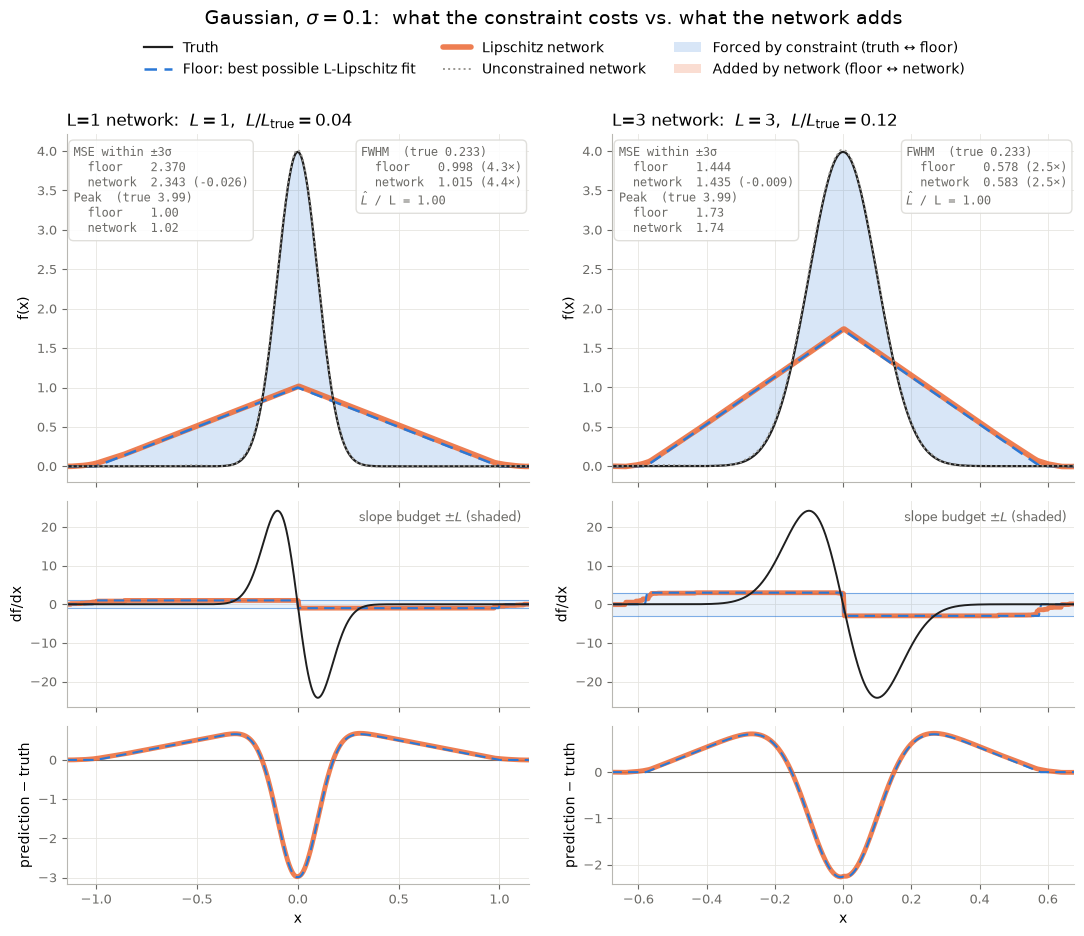

In [121]:
# Computing the floor and comparing it to the trained networks
from lipschitz_floor import lipschitz_floor

# Colours (validated categorical palette, slot 1 & 2) + neutral inks
C_TRUE, C_FLOOR, C_NET, C_REF, C_MUTED = "#1f1f1f", "#2a78d6", "#eb6834", "#9a9893", "#6b6a66"


def network_slope(model, x):
    """df/dx of the network at every point of x (shape (n, 1)), via autograd."""
    x = x.clone().detach().requires_grad_(True)
    grad, = torch.autograd.grad(model(x).sum(), x)
    return grad.detach().numpy().ravel()


def fwhm(x, f):
    """Full width at half maximum of a single peak on a zero baseline."""
    above = x[f >= 0.5 * f.max()]
    return above.max() - above.min()


def plot_floor_comparison(x, y_true, lipschitz_models, sigma, mu=0.0, reference_model=None, savepath=None):
    """
    One column per Lipschitz model. Rows:
      1) the fit: truth, best possible L-Lipschitz fit (floor), network. Shaded areas split the error into
         the part the constraint forces (truth <-> floor) and the part the network adds (floor <-> network).
      2) the slope: truth, floor and network slope against the slope budget [-L, L]
      3) the residuals (prediction - truth) for the floor and the network
    """
    x_np = x.detach().numpy().ravel()
    y_np = y_true.detach().numpy().ravel()
    slope_true = np.gradient(y_np, x_np)
    peak_region = np.abs(x_np - mu) < 3 * sigma

    ref_pred = None
    if reference_model is not None:
        with torch.no_grad():
            ref_pred = reference_model(x).numpy().ravel()

    n_cols = len(lipschitz_models)
    fig, axs = plt.subplots(3, n_cols, figsize=(6.5 * n_cols, 10), sharex="col",
                            gridspec_kw=dict(height_ratios=[2.2, 1.3, 1.0], hspace=0.08, wspace=0.18),
                            squeeze=False)
    summary = []

    for col, (name, model) in enumerate(lipschitz_models.items()):
        L = float(model.lipschitz_bound)
        with torch.no_grad():
            pred = model(x).numpy().ravel()
        slope_net = network_slope(model, x)
        floor_fit, _ = lipschitz_floor(x_np, y_np, L)
        slope_floor = np.gradient(floor_fit, x_np)

        # Metrics in the peak region (the tails are flat and would hide everything)
        mse_floor = np.mean((floor_fit - y_np)[peak_region] ** 2)
        mse_net = np.mean((pred - y_np)[peak_region] ** 2)
        L_hat = np.abs(slope_net).max()
        width_true, width_floor, width_net = fwhm(x_np, y_np), fwhm(x_np, floor_fit), fwhm(x_np, pred)
        summary.append(dict(name=name, L=L, mse_floor=mse_floor, mse_net=mse_net,
                            peak_true=y_np.max(), peak_floor=floor_fit.max(), peak_net=pred.max(),
                            fwhm_true=width_true, fwhm_floor=width_floor, fwhm_net=width_net, L_hat=L_hat))

        # Zoom: wherever the floor or the network differs visibly from the truth, at least +-4 sigma
        differs = np.maximum(np.abs(floor_fit - y_np), np.abs(pred - y_np)) > 0.01 * y_np.max()
        half_width = max(4 * sigma, 1.15 * np.abs(x_np[differs] - mu).max()) if differs.any() else 4 * sigma
        lo, hi = mu - half_width, mu + half_width

        # --- Row 1: the fit
        ax = axs[0, col]
        ax.fill_between(x_np, y_np, floor_fit, color=C_FLOOR, alpha=0.18, lw=0,
                        label="Forced by constraint (truth ↔ floor)")
        ax.fill_between(x_np, floor_fit, pred, color=C_NET, alpha=0.22, lw=0,
                        label="Added by network (floor ↔ network)")
        # The network is drawn wide and underneath, so the dashed floor stays visible when they overlap
        ax.plot(x_np, pred, color=C_NET, lw=4, alpha=0.85, solid_capstyle="round", label="Lipschitz network")
        ax.plot(x_np, floor_fit, color=C_FLOOR, lw=1.8, ls=(0, (5, 3)), label="Floor: best possible L-Lipschitz fit")
        ax.plot(x_np, y_np, color=C_TRUE, lw=1.6, label="Truth")
        if ref_pred is not None:
            ax.plot(x_np, ref_pred, color=C_REF, lw=1.4, ls=":", label="Unconstrained network")
        ax.set_title(rf"{name}:  $L = {L:g}$,  $L/L_\mathrm{{true}} = {L / np.abs(slope_true).max():.2f}$",
                     fontsize=12, loc="left")
        # Metrics in two small boxes, one in each upper corner, so they stay clear of the peak
        box = dict(va="top", fontsize=8.5, family="monospace", color=C_MUTED, transform=ax.transAxes,
                   bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#dddcd8", alpha=0.9))
        ax.text(0.015, 0.97,
                f"MSE within ±3σ\n"
                f"  floor    {mse_floor:.3f}\n"
                f"  network  {mse_net:.3f} ({mse_net - mse_floor:+.3f})\n"
                f"Peak  (true {y_np.max():.2f})\n"
                f"  floor    {floor_fit.max():.2f}\n"
                f"  network  {pred.max():.2f}", ha="left", **box)
        ax.text(0.985, 0.97,
                f"FWHM  (true {width_true:.3f})\n"
                f"  floor    {width_floor:.3f} ({width_floor / width_true:.1f}×)\n"
                f"  network  {width_net:.3f} ({width_net / width_true:.1f}×)\n"
                rf"$\hat{{L}}$ / L = {L_hat / L:.2f}", ha="right", multialignment="left", **box)
        ax.set_ylabel("f(x)")

        # --- Row 2: the slope against the slope budget
        ax = axs[1, col]
        ax.axhspan(-L, L, color=C_FLOOR, alpha=0.10, lw=0)
        ax.axhline(L, color=C_FLOOR, lw=0.8, alpha=0.6)
        ax.axhline(-L, color=C_FLOOR, lw=0.8, alpha=0.6)
        ax.plot(x_np, slope_net, color=C_NET, lw=3.5, alpha=0.85)
        ax.plot(x_np, slope_floor, color=C_FLOOR, lw=1.5, ls=(0, (5, 3)))
        ax.plot(x_np, slope_true, color=C_TRUE, lw=1.4)
        ax.text(0.985, 0.95, r"slope budget $\pm L$ (shaded)", transform=ax.transAxes, ha="right", va="top",
                fontsize=9, color=C_MUTED)
        ax.set_ylabel("df/dx")

        # --- Row 3: residuals
        ax = axs[2, col]
        ax.axhline(0, color=C_MUTED, lw=0.8)
        ax.plot(x_np, pred - y_np, color=C_NET, lw=3.5, alpha=0.85)
        ax.plot(x_np, floor_fit - y_np, color=C_FLOOR, lw=1.5, ls=(0, (5, 3)))
        ax.set_ylabel("prediction − truth")
        ax.set_xlabel("x")

        for a in axs[:, col]:
            a.set_xlim(lo, hi)
            a.grid(True, color="#e6e5e1", lw=0.6)
            a.set_axisbelow(True)
            for side in ("top", "right"):
                a.spines[side].set_visible(False)
            for side in ("left", "bottom"):
                a.spines[side].set_color("#b8b7b2")
            a.tick_params(colors=C_MUTED, labelsize=9)

    handles, labels = axs[0, 0].get_legend_handles_labels()
    order = ["Truth", "Floor: best possible L-Lipschitz fit", "Lipschitz network", "Unconstrained network",
             "Forced by constraint (truth ↔ floor)", "Added by network (floor ↔ network)"]
    by_label = dict(zip(labels, handles))
    order = [label for label in order if label in by_label]
    fig.legend([by_label[label] for label in order], order, loc="lower center", ncol=3, frameon=False,
               fontsize=10, bbox_to_anchor=(0.5, 0.905))
    fig.suptitle(rf"Gaussian, $\sigma = {sigma:g}$:  what the constraint costs vs. what the network adds",
                 y=0.985, fontsize=14)
    fig.subplots_adjust(top=0.86)
    if savepath is not None:
        fig.savefig(savepath, bbox_inches="tight")
    plt.show()
    return summary


summary = plot_floor_comparison(
    x_gaussian_linspace, y_gaussian_linspace,
    lipschitz_models={"L=1 network": Lipschitz_1_model, "L=3 network": Lipschitz_3_model},
    sigma=SIGMA, mu=MU,
    reference_model=Unconstrained_model,
    savepath="Plots/gaussian_floor_comparison.pdf",
)

In [ ]:
# Setting up the heatmap search for different Lipschitz constants and Gaussian widths
lipschitz_constants = [0.5, 1.0, 2.0, 3.0, 5.0]
gaussian_widths = [0.05, 0.1, 0.2, 0.5, 1.0, 2.0] # Do not go higher here yet as the range is (-5, 5)

def gridsearch(lipschitz_constants, gaussian_widths, N = 1000, noise_magnitude=0.05, mu=0):
    # Storing results in a nested dictionary for better organization
    results = {}
    for L in lipschitz_constants:
        results[L] = {}
        for sigma in gaussian_widths:
            results[L][sigma] = None  # Placeholder for the final prediction metric

    for i, L in enumerate(lipschitz_constants):
        for j, sigma in enumerate(gaussian_widths):
            # Generate Gaussian data
            x_train, y_train, x_linspace, y_linspace = gaussian_function_data(N=1000, mu=0, sigma=sigma, noise_magnitude=0.05)

            # Set up the model with its hyperparameters and optimizer
            model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, n_groups=N_GROUPS, depth = DEPTH, lipschitz_bound=L)
            optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

            # Train the model and evaluate it on the validation set

            # Predict

            # Calculate performance metrics

            # Store the final validation loss in the results array
            results[i, j] = val_losses_L[-1]

    return results

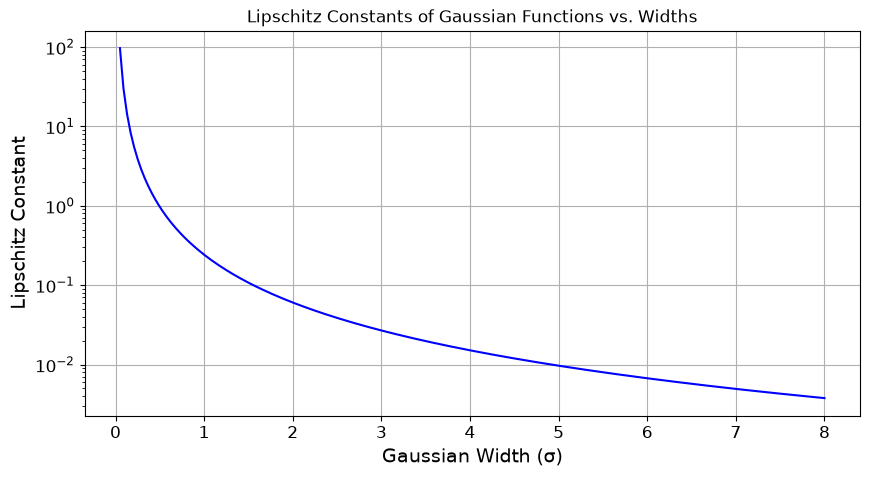

In [167]:

sigma_arrays = np.linspace(0.05, 8.0, 200)  # Gaussian widths
lipschitz_arrays = gaussian_lipschitz_constant(sigma_arrays)  # Lipschitz constants

plt.figure(figsize=(10, 5))
plt.plot(sigma_arrays, lipschitz_arrays, '-', color='blue')

plt.xlabel('Gaussian Width (σ)', fontsize=14)
plt.ylabel('Lipschitz Constant', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.yscale('log')
plt.grid()
plt.savefig('Plots/gaussian_lipschitz_constants.pdf')
plt.title('Lipschitz Constants of Gaussian Functions vs. Widths')
plt.show()